# Nhận diện khuôn mặt thời gian thực với MTCNN và FaceNet

## 1. Giới thiệu

Hệ thống dùng OpenCV, MTCNN và FaceNet: phát hiện khuôn mặt từ khung hình webcam, căn chỉnh, trích xuất vector đặc trưng 128 chiều rồi so với khuôn mặt tham chiếu bằng độ tương đồng cosine.

**Quy tắc quyết định:** similarity > 0.7 → `Matched`; ngược lại → `Unknown`.

**Quy trình:** Webcam/Ảnh → MTCNN → Căn chỉnh mặt → FaceNet (128D) → Cosine → Matched / Unknown

**Phạm vi notebook:** đánh giá từng bước trên ảnh tĩnh (gồm 1 ảnh tham chiếu và 2 ảnh kiểm thử):

1. Phát hiện mặt và điểm mốc (MTCNN)
2. Căn chỉnh mặt
3. Trích xuất đặc trưng (FaceNet)
4. So khớp bằng cosine
5. Đối chứng: có và không căn chỉnh

Giả định: cả 3 ảnh là **cùng một người**.

## 2. Môi trường và dữ liệu

### 2.1. Thiết lập

Notebook dùng lại các module trong `src/`, không cài đặt lại thuật toán.

In [1]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd().resolve()

# Xác định thư mục gốc project
if (CURRENT_DIR / "src").is_dir():
    ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "src").is_dir():
    ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Không tìm thấy thư mục src. Kiểm tra vị trí chạy notebook."
    )

# Cho phép import các module trong src/
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Current directory:", CURRENT_DIR)
print("ROOT:", ROOT)
print("Reference path:", ROOT / "data/reference/image.jpg")

Current directory: C:\Users\NAO\Downloads\lab5_face_ID\document
ROOT: C:\Users\NAO\Downloads\lab5_face_ID
Reference path: C:\Users\NAO\Downloads\lab5_face_ID\data\reference\image.jpg


In [2]:
# Standard library
import sys
from pathlib import Path

# Third-party libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Project modules
from src.config import REFERENCE_PATH, SIMILARITY_THRESHOLD
from src.face_detector import FaceDetector
from src.face_alignment import align_face
from src.face_embedder import FaceEmbedder
from src.face_matcher import FaceMatcher
from src.visualizer import draw_results

### 2.2. Dữ liệu

| Tên | Tệp | Đặc điểm |
|---|---|---|
| Reference | `data/reference/image.jpg` | Ảnh tham chiếu, đầu nghiêng, nền tường |
| Test 1 | `data/evaluation/image1.jpg` | Nhìn thẳng, ánh sáng sân khấu, có logo và banner quảng cáo |
| Test 2 | `data/evaluation/image2.jpg` | Đeo kính, một tay chạm gọng kính, nền tối |

Ảnh được đọc bằng OpenCV (BGR), chỉ đổi sang RGB khi hiển thị bằng Matplotlib.

**Phân biệt đường dẫn:** phần minh họa này dùng `data/reference/image.jpg`, trong khi `main.py` dùng `data/reference/my_face.jpg` theo `src/config.py`. Hai ảnh có thể khác nhau; muốn đối chiếu trực tiếp cần dùng cùng một ảnh và chạy lại các cell liên quan.

In [3]:
IMAGE_PATHS = {
    "Reference": ROOT / "data/reference/image.jpg",
    "Test 1": ROOT / "data/evaluation/image1.jpg",
    "Test 2": ROOT / "data/evaluation/image2.jpg",
}

for name, path in IMAGE_PATHS.items():
    assert path.is_file(), f"Image not found: {path}"
    print(f"{name}: FOUND")

Reference: FOUND
Test 1: FOUND
Test 2: FOUND


In [4]:
# Nạp ảnh
images = {}

for name, path in IMAGE_PATHS.items():
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    images[name] = image

    print(f"{name}: {image.shape}")

Reference: (447, 447, 3)
Test 1: (640, 480, 3)
Test 2: (447, 447, 3)


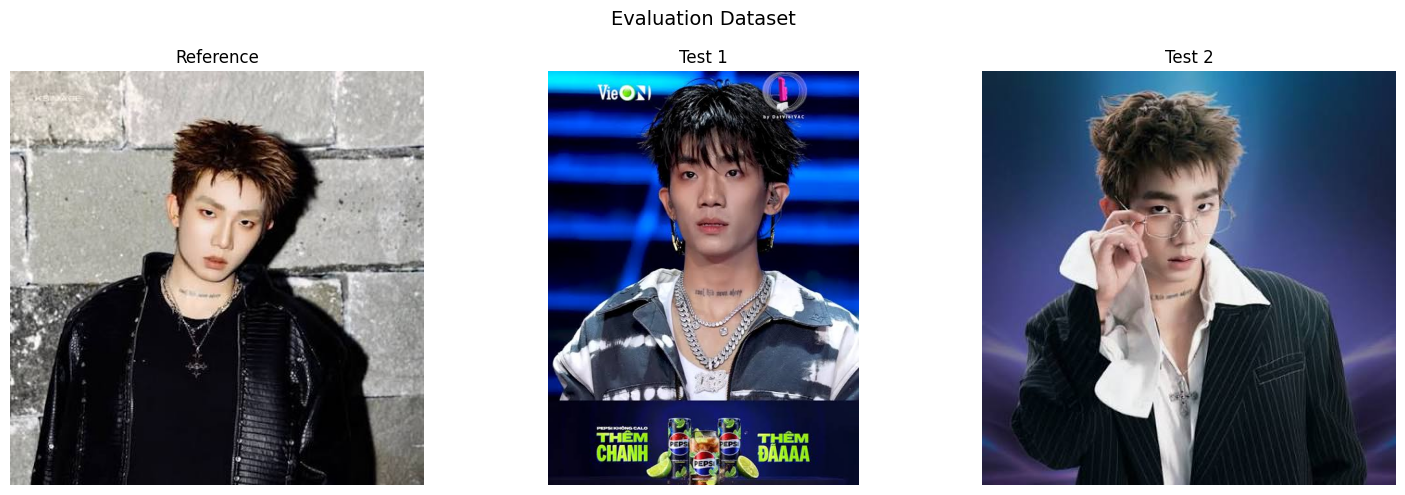

In [5]:
# Trực quan hóa ảnh đầu vào
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, image) in zip(axes, images.items()):
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(rgb_image)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Evaluation Dataset", fontsize=14)
plt.tight_layout()
plt.show()

**Nhận xét:** Cả 3 ảnh được nạp thành công. Hai ảnh kiểm thử khác ảnh tham chiếu về nền, ánh sáng và phụ kiện (kính), nên phép thử gần với điều kiện thực tế hơn so với ảnh chụp cùng bối cảnh.

## 3. Phát hiện khuôn mặt bằng MTCNN

### 3.1. Phương pháp

MTCNN trả về với mỗi khuôn mặt:

- **Hộp bao** `(x, y, w, h)`
- **Độ tin cậy** của phát hiện
- **5 điểm mốc:** mắt trái, mắt phải, mũi, hai khóe miệng

Các điểm mốc được dùng để căn chỉnh mặt ở Mục 4.

In [6]:
detector = FaceDetector()

detection_results = {}

for name, image in images.items():
    faces = detector.detect(image)
    detection_results[name] = faces

    print(f"\n{name}: {len(faces)} face(s) detected")

    for i, face in enumerate(faces):
        print(f"  Face {i + 1}")
        print(f"  Box: {face['box']}")
        print(f"  Confidence: {face['confidence']:.4f}")
        print(f"  Keypoints: {face['keypoints']}")


Reference: 1 face(s) detected
  Face 1
  Box: [187, 103, 86, 127]
  Confidence: 0.9893
  Keypoints: {'nose': [np.int64(231), np.int64(186)], 'mouth_right': [np.int64(236), np.int64(206)], 'right_eye': [np.int64(255), np.int64(164)], 'left_eye': [np.int64(216), np.int64(153)], 'mouth_left': [np.int64(209), np.int64(200)]}

Test 1: 1 face(s) detected
  Face 1
  Box: [183, 97, 142, 185]
  Confidence: 0.9998
  Keypoints: {'nose': [np.int64(252), np.int64(198)], 'mouth_right': [np.int64(278), np.int64(237)], 'right_eye': [np.int64(285), np.int64(157)], 'left_eye': [np.int64(219), np.int64(159)], 'mouth_left': [np.int64(228), np.int64(236)]}

Test 2: 1 face(s) detected
  Face 1
  Box: [157, 95, 97, 138]
  Confidence: 0.9999
  Keypoints: {'nose': [np.int64(220), np.int64(181)], 'mouth_right': [np.int64(228), np.int64(202)], 'right_eye': [np.int64(236), np.int64(147)], 'left_eye': [np.int64(192), np.int64(150)], 'mouth_left': [np.int64(200), np.int64(204)]}


3.3. Experimental Results

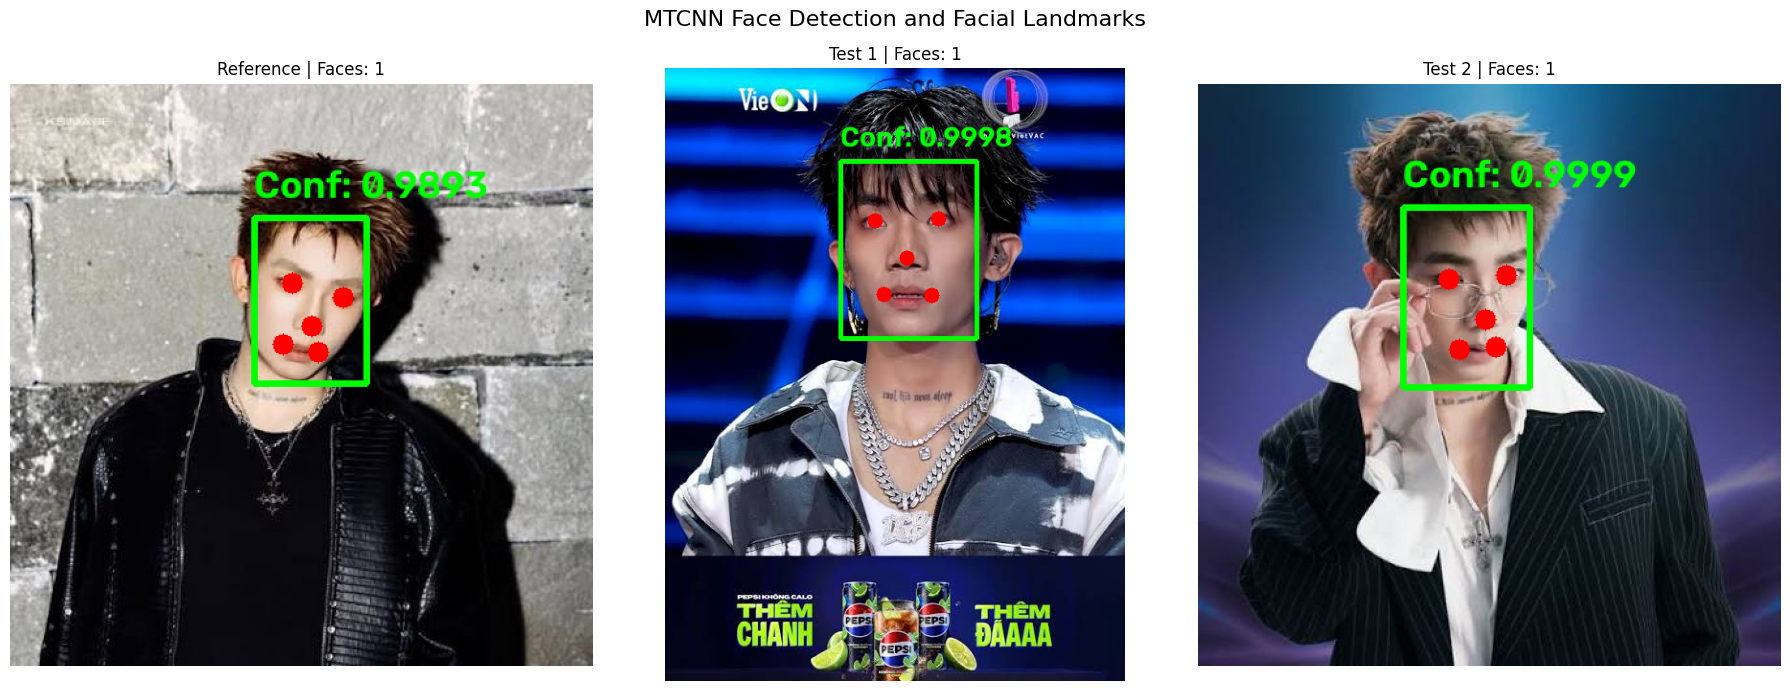

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (name, image) in zip(axes, images.items()):
    display = image.copy()

    for face in detection_results[name]:
        x, y, w, h = map(int, face["box"])
        confidence = float(face["confidence"])

        # Bounding box
        cv2.rectangle(
            display,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

        # Detection confidence
        cv2.putText(
            display,
            f"Conf: {confidence:.4f}",
            (x, max(y - 15, 30)),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            3
        )

        # Five facial landmarks
        for point in face["keypoints"].values():
            px, py = map(int, point)
            cv2.circle(display, (px, py), 8, (0, 0, 255), -1)

    display_rgb = cv2.cvtColor(display, cv2.COLOR_BGR2RGB)

    ax.imshow(display_rgb)
    ax.set_title(
        f"{name} | Faces: {len(detection_results[name])}"
    )
    ax.axis("off")

plt.suptitle("MTCNN Face Detection and Facial Landmarks", fontsize=16)
plt.tight_layout()
plt.show()

Nhận xét

MTCNN phát hiện đúng 1 khuôn mặt ở cả 3 ảnh. Độ tin cậy: Reference **0.9893**, Test 1 **0.9998**, Test 2 **0.9999**.

Logo, banner (Test 1) và kính, bàn tay (Test 2) không gây phát hiện nhầm hay làm mất điểm mốc. Reference có độ tin cậy thấp nhất, có thể do đầu nghiêng và khuôn mặt nhỏ hơn. Kết quả chỉ trên 3 ảnh nên chưa phản ánh độ chính xác tổng quát.

## 4. Căn chỉnh khuôn mặt

### 4.1. Phương pháp

Dùng hai điểm mốc mắt để xoay ảnh bù độ nghiêng đầu, rồi cắt vùng mặt làm đầu vào cho FaceNet:

1. Lấy toạ độ hai mắt.
2. Tính góc giữa hai mắt.
3. Xoay ảnh để hai mắt nằm ngang.
4. Cắt vùng mặt.

### 4.2. Kết quả

In [8]:
aligned_faces = {}
original_faces = {}

for name, image in images.items():
    faces = detection_results[name]

    if len(faces) == 0:
        print(f"{name}: No face detected")
        continue

    # Chọn khuôn mặt có confidence cao nhất
    face = max(faces, key=lambda f: f["confidence"])

    x, y, w, h = map(int, face["box"])

    # Giới hạn tọa độ trong kích thước ảnh
    height, width = image.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)

    original_crop = image[y1:y2, x1:x2].copy()

    # Gọi module alignment của project
    aligned_crop = align_face(image, face)

    if original_crop.size == 0 or aligned_crop is None or aligned_crop.size == 0:
        print(f"{name}: Invalid face crop")
        continue

    original_faces[name] = original_crop
    aligned_faces[name] = aligned_crop

    print(f"{name}")
    print(f"  Original shape: {original_crop.shape}")
    print(f"  Aligned shape:  {aligned_crop.shape}")

Reference
  Original shape: (127, 86, 3)
  Aligned shape:  (160, 160, 3)
Test 1
  Original shape: (185, 142, 3)
  Aligned shape:  (160, 160, 3)
Test 2
  Original shape: (138, 97, 3)
  Aligned shape:  (160, 160, 3)


### 4.3. Visualization

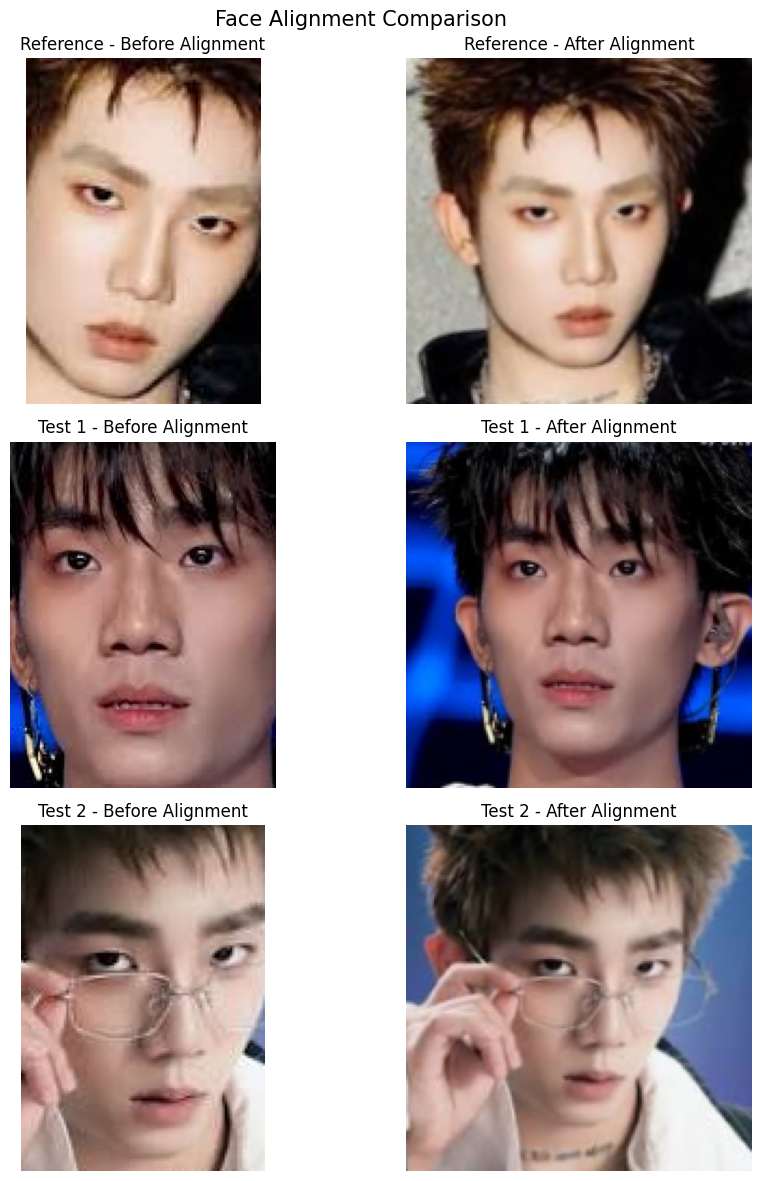

In [9]:
names = list(aligned_faces.keys())

fig, axes = plt.subplots(
    len(names), 2,
    figsize=(10, 4 * len(names)),
    squeeze=False
)

for i, name in enumerate(names):
    before = original_faces[name]
    after = aligned_faces[name]

    axes[i, 0].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{name} - Before Alignment")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{name} - After Alignment")
    axes[i, 1].axis("off")

plt.suptitle("Face Alignment Comparison", fontsize=15)
plt.tight_layout()
plt.show()

### 4.4. Kiểm tra góc nghiêng hai mắt

In [10]:
angles = {}

for name, faces in detection_results.items():
    if not faces:
        continue

    face = max(faces, key=lambda f: f["confidence"])

    left_eye = np.array(face["keypoints"]["left_eye"], dtype=float)
    right_eye = np.array(face["keypoints"]["right_eye"], dtype=float)

    dx = right_eye[0] - left_eye[0]
    dy = right_eye[1] - left_eye[1]

    angle = np.degrees(np.arctan2(dy, dx))
    angles[name] = angle

    print(f"{name}: Eye-line angle = {angle:.2f} degrees")

Reference: Eye-line angle = 15.75 degrees
Test 1: Eye-line angle = -1.74 degrees
Test 2: Eye-line angle = -3.90 degrees


Nhận xét

Góc nghiêng hai mắt: Reference **15.75°**, Test 1 **−1.74°**, Test 2 **−3.90°**. Chỉ ảnh tham chiếu bị nghiêng rõ, hai ảnh kiểm thử gần như thẳng.

Sau căn chỉnh, vùng cắt lớn hơn bản gốc (ví dụ Reference từ 127×86 lên 147×119). Vì vậy kết quả ở Mục 7 phản ánh cả việc xoay lẫn thay đổi cách cắt.

## 5. Trích xuất đặc trưng bằng FaceNet

### 5.1. Phương pháp

FaceNet (đã huấn luyện sẵn) biến mỗi khuôn mặt đã căn chỉnh thành vector **128 chiều**. Module `FaceEmbedder` xử lý tiền xử lý và suy luận.

### 5.2. Kết quả

In [11]:
embedder = FaceEmbedder()

embeddings = {}

for name, face_image in aligned_faces.items():
    embedding = embedder.extract(face_image)

    embeddings[name] = embedding

    print(f"\n{name}")
    print(f"  Shape: {embedding.shape}")
    print(f"  Dtype: {embedding.dtype}")
    print(f"  L2 norm: {np.linalg.norm(embedding):.4f}")
    print(f"  First 5 values: {embedding[:5]}")


Reference
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.8530
  First 5 values: [ 0.49309576 -0.347875   -0.6549412  -0.9323443   0.74758035]

Test 1
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.7685
  First 5 values: [ 1.0948336 -0.7253735 -1.9043562  1.0843073  0.5091091]

Test 2
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.1428
  First 5 values: [ 0.34900826 -0.04457633 -0.8543139  -0.36330035  0.52671283]


In [12]:
for name, embedding in embeddings.items():
    assert embedding.shape == (128,), f"{name}: Invalid embedding shape"
    assert np.all(np.isfinite(embedding)), f"{name}: Non-finite values"

    print(f"{name}: PASS")

Reference: PASS
Test 1: PASS
Test 2: PASS


5.3. Visualization — Biểu diễn vector đặc trưng

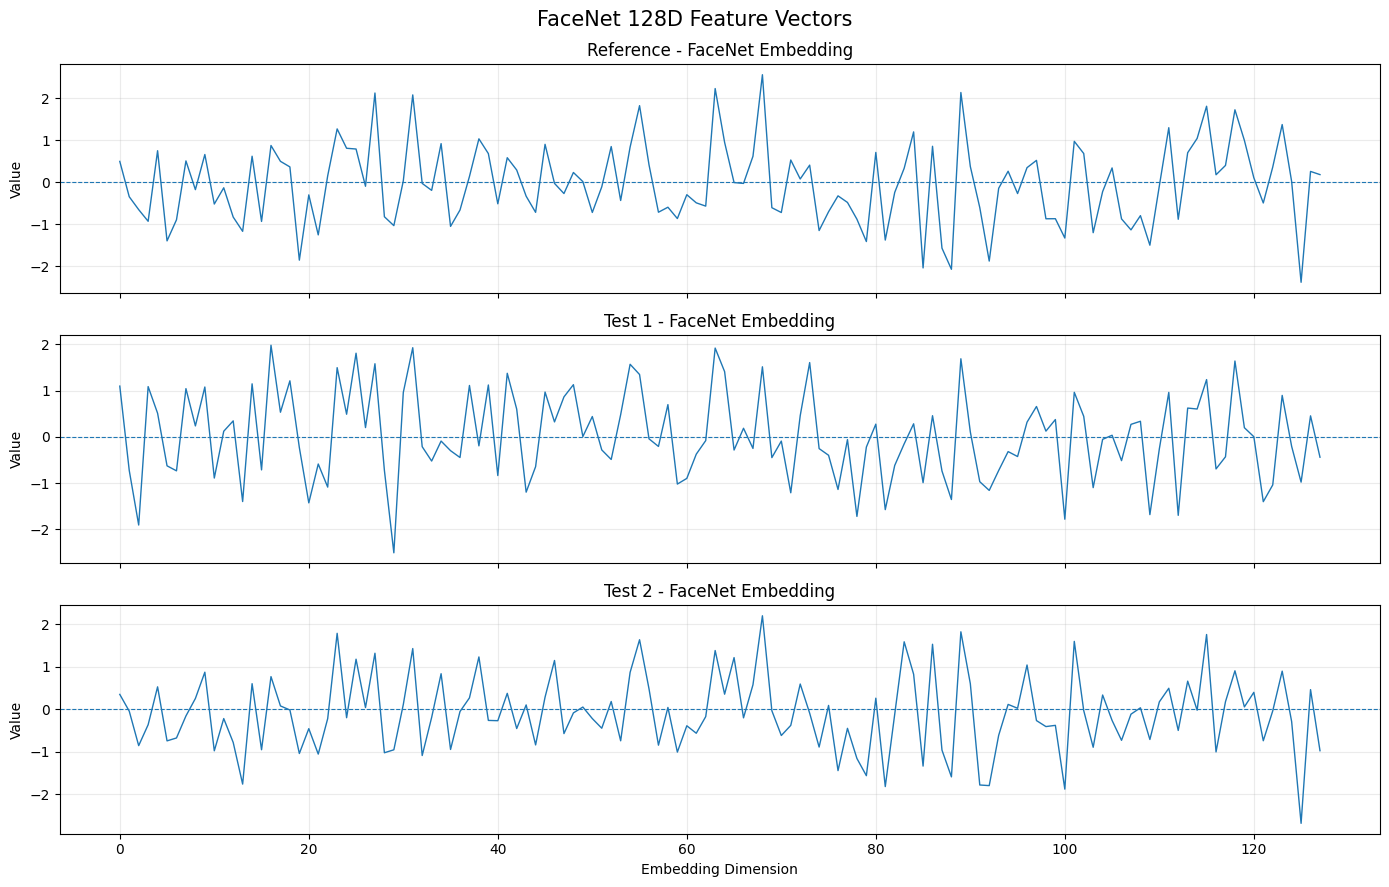

In [13]:
fig, axes = plt.subplots(
    len(embeddings), 1,
    figsize=(14, 9),
    sharex=True,
    squeeze=False
)

for ax, (name, embedding) in zip(axes.flat, embeddings.items()):
    ax.plot(np.arange(128), embedding, linewidth=1)
    ax.axhline(0, linestyle="--", linewidth=0.8)
    ax.set_title(f"{name} - FaceNet Embedding")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.25)

axes[-1, 0].set_xlabel("Embedding Dimension")
plt.suptitle("FaceNet 128D Feature Vectors", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét

Cả 3 vector có kích thước `(128,)`, giá trị hữu hạn. Chuẩn L2 khoảng 10.4–10.9 (vector chưa chuẩn hóa), không ảnh hưởng đến cosine vì cosine chỉ xét hướng. Từng chiều riêng lẻ không có ý nghĩa trực quan; cần so sánh hai vector bằng độ đo cosine (Mục 6).

## 6. So khớp bằng độ tương đồng cosine

### 6.1. Phương pháp

Cosine đo góc giữa hai vector đặc trưng. Vector tham chiếu được so với vector của Test 1 và Test 2.

- similarity > 0.7 → `Matched`
- similarity ≤ 0.7 → `Unknown`

Ngưỡng 0.7 do đề bài quy định, chưa được tối ưu bằng dữ liệu kiểm định.

### 6.2. Kết quả

In [14]:
reference_embedding = embeddings["Reference"]

similarity_results = {}

for name, test_embedding in embeddings.items():

    if name == "Reference":
        continue

    similarity = float(
        np.dot(reference_embedding, test_embedding)
        / (
            np.linalg.norm(reference_embedding)
            * np.linalg.norm(test_embedding)
        )
    )

    label = (
        "Matched"
        if similarity >= SIMILARITY_THRESHOLD
        else "Unknown"
    )

    similarity_results[name] = {
        "similarity": similarity,
        "label": label
    }

    print(f"{name}: {similarity:.4f} → {label}")

Test 1: 0.7027 → Matched
Test 2: 0.8307 → Matched


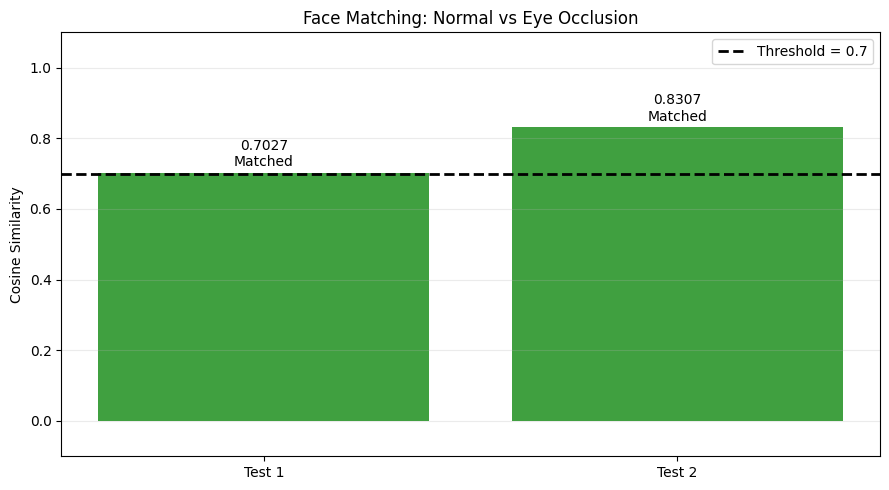

In [15]:
names = list(similarity_results.keys())

scores = [
    similarity_results[name]["similarity"]
    for name in names
]

labels = [
    similarity_results[name]["label"]
    for name in names
]

colors = [
    "green" if label == "Matched" else "red"
    for label in labels
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(names, scores, color=colors, alpha=0.75)

ax.axhline(
    SIMILARITY_THRESHOLD,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {SIMILARITY_THRESHOLD}"
)

for bar, score, label in zip(bars, scores, labels):
    ax.annotate(
        f"{score:.4f}\n{label}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_ylabel("Cosine Similarity")
ax.set_title("Face Matching: Normal vs Eye Occlusion")
ax.set_ylim(min(-0.1, min(scores) - 0.15), 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 6.3. Nhận xét

| Ảnh | Cosine | Dự đoán |
|---|---:|---|
| Test 1 | 0.7027 | Matched |
| Test 2 | 0.8307 | Matched |

Cả hai ảnh có cosine ≥ 0.70 nên được **dự đoán** `Matched`. Test 1 chỉ cao hơn ngưỡng 0.0027 nên kết quả có thể nhạy với điều kiện ảnh và thay đổi xử lý. **Không khẳng định dự đoán đúng** khi chưa xác nhận danh tính thực tế (`ground_truth`).

## 7. Thí nghiệm đối chứng: ảnh hưởng của căn chỉnh

### 7.1. Thiết kế

So sánh hai cấu hình, cùng ảnh, cùng mô hình, cùng ngưỡng 0.7:

- **Có căn chỉnh:** MTCNN → căn chỉnh → FaceNet → cosine
- **Không căn chỉnh:** MTCNN → cắt mặt → FaceNet → cosine

### 7.2. Kết quả

In [16]:
embeddings_no_alignment = {}

for name, face_image in original_faces.items():
    embedding = embedder.extract(face_image)

    assert embedding.shape == (128,)
    assert np.all(np.isfinite(embedding))

    embeddings_no_alignment[name] = embedding

    print(f"{name}: {embedding.shape} - PASS")

Reference: (128,) - PASS
Test 1: (128,) - PASS
Test 2: (128,) - PASS


In [17]:
ablation_results = {}

ref = embeddings_no_alignment["Reference"]

for name in similarity_results.keys():

    # With alignment: kết quả từ Section 6
    sim_aligned = similarity_results[name]["similarity"]

    # Without alignment
    test = embeddings_no_alignment[name]

    sim_no_alignment = float(
        np.dot(ref, test)
        / (
            np.linalg.norm(ref)
            * np.linalg.norm(test)
        )
    )

    ablation_results[name] = {
        "With Alignment": sim_aligned,
        "Without Alignment": sim_no_alignment,
        "Difference": sim_aligned - sim_no_alignment
    }

    print(
        f"{name}: "
        f"Aligned = {sim_aligned:.4f} | "
        f"No Alignment = {sim_no_alignment:.4f} | "
        f"Difference = {sim_aligned - sim_no_alignment:+.4f}"
    )

Test 1: Aligned = 0.7027 | No Alignment = 0.6036 | Difference = +0.0991
Test 2: Aligned = 0.8307 | No Alignment = 0.8038 | Difference = +0.0269


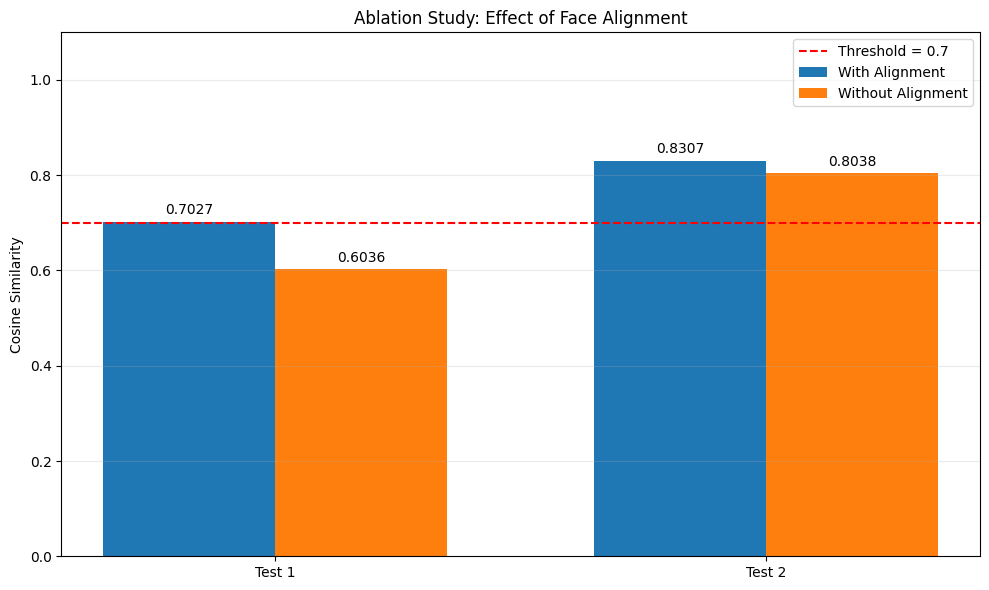

In [18]:
names = list(ablation_results.keys())

with_alignment = [
    ablation_results[name]["With Alignment"]
    for name in names
]

without_alignment = [
    ablation_results[name]["Without Alignment"]
    for name in names
]

x = np.arange(len(names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    with_alignment,
    width,
    label="With Alignment"
)

bars2 = ax.bar(
    x + width / 2,
    without_alignment,
    width,
    label="Without Alignment"
)

ax.axhline(
    SIMILARITY_THRESHOLD,
    color="red",
    linestyle="--",
    label=f"Threshold = {SIMILARITY_THRESHOLD}"
)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Cosine Similarity")
ax.set_title("Ablation Study: Effect of Face Alignment")
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 7.3. Nhận xét thí nghiệm căn chỉnh

| Ảnh | Có căn chỉnh | Không căn chỉnh | Chênh lệch |
|---|---:|---:|---:|
| Test 1 | 0.7027 | 0.6036 | +0.0991 |
| Test 2 | 0.8307 | 0.8038 | +0.0269 |

Căn chỉnh làm tăng cosine trên cả hai ảnh thử trong lần chạy này. Với Test 1, dự đoán đổi từ `Unknown` (0.6036) thành `Matched` (0.7027); Test 2 giữ nguyên `Matched`. Kết quả chỉ minh họa ba ảnh và còn chịu ảnh hưởng của **thay đổi vùng crop**, không thể quy toàn bộ chênh lệch cho phép xoay ảnh.

## 8. Đánh giá tổng hợp thí nghiệm ba ảnh

### 8.1. Bảng tổng hợp

`Prediction` là kết quả dự đoán theo ngưỡng 0.70. `Expected`/`Correct` chỉ có ý nghĩa khi xác nhận được danh tính thực tế của Test 1 và Test 2. Nếu chưa xác minh, giữ `None` và **không tính độ chính xác** cho thí nghiệm này.

In [19]:
import pandas as pd
from IPython.display import display as show_table

# Ground truth: cập nhật theo danh tính thực tế của từng ảnh
# "Matched": cùng người với ảnh Reference
# "Unknown": người khác với ảnh Reference
ground_truth = {
    "Test 1": None,
    "Test 2": None,
}

summary_rows = []

for name, result in similarity_results.items():

    similarity = result["similarity"]
    prediction = result["label"]
    expected = ground_truth.get(name)

    faces = detection_results.get(name, [])

    detection_confidence = (
        max(face["confidence"] for face in faces)
        if faces else None
    )

    correct = (
        prediction == expected
        if expected is not None
        else None
    )

    summary_rows.append({
        "Test Image": name,
        "Detection Confidence": detection_confidence,
        "Similarity (Aligned)": similarity,
        "Similarity (No Alignment)": ablation_results[name]["Without Alignment"],
        "Prediction": prediction,
        "Expected": expected,
        "Correct": correct
    })

summary_df = pd.DataFrame(summary_rows)

show_table(summary_df.round(4))

,Test Image,Detection Confidence,Similarity (Aligned),Similarity (No Alignment),Prediction,Expected,Correct
0,Test 1,0.9998,0.7027,0.6036,Matched,None,None
1,Test 2,0.9999,0.8307,0.8038,Matched,None,None


### 8.2. Hạn chế

- Chỉ có một ảnh tham chiếu và hai ảnh thử; `ground_truth` chưa xác nhận nên không tính accuracy cho thí nghiệm ba ảnh.
- Test 1 có cosine 0.7027, chỉ vượt ngưỡng 0.0027.
- Ngưỡng 0.70 được giữ cố định theo bài thực hành, chưa hiệu chỉnh trên tập validation độc lập.
- So sánh căn chỉnh thay đổi cả góc quay và vùng crop.
- Chưa đánh giá có hệ thống ảnh hưởng ánh sáng, góc mặt, che khuất và khoảng cách camera trong thí nghiệm ba ảnh.

### 8.3. Kết luận thí nghiệm minh họa

MTCNN phát hiện một khuôn mặt trong mỗi ảnh (confidence 0.9893, 0.9998, 0.9999). FaceNet tạo embedding 128 chiều và bộ so khớp cho ra Test 1 = 0.7027, Test 2 = 0.8307; cả hai được dự đoán `Matched`. Căn chỉnh làm tăng cosine so với không căn chỉnh trong hai phép thử, nhưng đây không phải kết quả định lượng tổng quát về nhận diện.

### 8.4. Hướng mở rộng

Đánh giá trên nhiều người bằng cặp Same/Different (Phần 9), phân tích tốc độ webcam (Phần 10), sau đó xem xét tập validation riêng và đánh giá tracking định lượng.

## 9. Đánh giá Face Matching theo cặp ảnh (Georgia Tech)

Sử dụng `data/pair_evaluation/pairs.csv` đã chuẩn bị trước, gồm `image1`, `image2`, `label` (1 = Same, 0 = Different). Notebook 01 kiểm tra dữ liệu và file cặp ảnh, **không tự tạo lại file**.

- 100 cặp gồm 50 Same và 50 Different; 91 ảnh duy nhất, có ảnh lặp giữa các cặp.
- Ảnh nằm trong `data/gt_db/`, đường dẫn CSV tính từ thư mục gốc.
- Pipeline: MTCNN → Alignment → FaceNet → cosine → Same/Different.
- Ngưỡng cố định 0.70, không tối ưu trên chính tập đánh giá.
- Đây là **pair verification**, khác với việc webcam so khớp với một ảnh tham chiếu và khác với đánh giá độ chính xác của tracking.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

# ============================================================
# 1. XÁC ĐỊNH THƯ MỤC GỐC PROJECT
# ============================================================

ROOT = Path.cwd().resolve()

# Tìm ngược lên đến khi thấy data/gt_db
while not (ROOT / "data" / "gt_db").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError(
            "Không tìm thấy thư mục gốc project chứa data/gt_db"
        )
    ROOT = ROOT.parent

print("Project root:", ROOT)


# ============================================================
# 2. KHAI BÁO ĐƯỜNG DẪN
# ============================================================

PAIRS_CSV = ROOT / "data" / "pair_evaluation" / "pairs.csv"
OUTPUT_DIR = ROOT / "outputs" / "evaluation"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Pairs CSV:", PAIRS_CSV)
print("CSV exists:", PAIRS_CSV.is_file())

if not PAIRS_CSV.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy {PAIRS_CSV}. "
        "Hãy kiểm tra Cell 5 của notebook 01."
    )


# ============================================================
# 3. ĐỌC DỮ LIỆU PAIRS
# ============================================================

pairs = pd.read_csv(
    PAIRS_CSV,
    dtype={
        "image1": str,
        "image2": str,
        "label": int
    }
)

required = {"image1", "image2", "label"}

assert required.issubset(pairs.columns), (
    f"Thiếu cột: {required - set(pairs.columns)}"
)

assert len(pairs) == 100, (
    f"Dự kiến 100 cặp, hiện có {len(pairs)}"
)

assert set(pairs["label"]) == {0, 1}, (
    "Nhãn phải là 0 hoặc 1"
)

assert (pairs["image1"] != pairs["image2"]).all(), (
    "Có cặp ảnh trùng chính nó"
)

assert (
    (pairs["label"] == 1).sum() == 50
    and (pairs["label"] == 0).sum() == 50
), "Số lượng Positive/Negative không đúng"


# ============================================================
# 4. KIỂM TRA ĐƯỜNG DẪN ẢNH
# ============================================================

# Hỗ trợ đường dẫn Windows có dấu \
def resolve_image(relative_path):
    normalized = str(relative_path).replace("\\", "/")
    return ROOT.joinpath(*normalized.split("/"))


unique_files = sorted(
    set(pairs["image1"]) | set(pairs["image2"])
)

missing_files = [
    name
    for name in unique_files
    if not resolve_image(name).is_file()
]

assert not missing_files, (
    f"Thiếu {len(missing_files)} ảnh, "
    f"ví dụ: {missing_files[:3]}"
)


# ============================================================
# 5. KIỂM TRA NHÃN POSITIVE / NEGATIVE
# ============================================================

person1 = pairs["image1"].map(
    lambda p: Path(
        str(p).replace("\\", "/")
    ).parent.name
)

person2 = pairs["image2"].map(
    lambda p: Path(
        str(p).replace("\\", "/")
    ).parent.name
)

assert (
    (person1 == person2).astype(int) == pairs["label"]
).all(), "Nhãn không khớp danh tính"


# ============================================================
# 6. CHUẨN HÓA TÊN CỘT CHO NOTEBOOK 02
# ============================================================

pairs = pairs.rename(
    columns={
        "image1": "image_a",
        "image2": "image_b"
    }
)

pairs["label"] = pairs["label"].map({
    1: "Same",
    0: "Different"
})


# ============================================================
# 7. HIỂN THỊ KẾT QUẢ
# ============================================================

display(pairs.head(10))

print("\n========== DATASET SUMMARY ==========")
print("Total pairs:", len(pairs))
print("Positive (Same):", (pairs["label"] == "Same").sum())
print("Negative (Different):", (pairs["label"] == "Different").sum())
print("Unique images:", len(unique_files))
print("Missing images:", len(missing_files))
print("Dataset validation: PASSED")

Project root: C:\Users\NAO\Downloads\lab5_face_ID
Pairs CSV: C:\Users\NAO\Downloads\lab5_face_ID\data\pair_evaluation\pairs.csv
CSV exists: True


,image_a,image_b,label
0,data\gt_db\s18\01.jpg,data\gt_db\s18\10.jpg,Same
1,data\gt_db\s15\01.jpg,data\gt_db\s15\13.jpg,Same
2,data\gt_db\s02\14.jpg,data\gt_db\s09\15.jpg,Different
3,data\gt_db\s18\04.jpg,data\gt_db\s41\01.jpg,Different
4,data\gt_db\s02\15.jpg,data\gt_db\s02\05.jpg,Same
5,data\gt_db\s08\08.jpg,data\gt_db\s41\01.jpg,Different
6,data\gt_db\s09\14.jpg,data\gt_db\s09\05.jpg,Same
7,data\gt_db\s09\11.jpg,data\gt_db\s09\13.jpg,Same
8,data\gt_db\s07\10.jpg,data\gt_db\s07\04.jpg,Same
9,data\gt_db\s08\04.jpg,data\gt_db\s16\06.jpg,Different



========== DATASET SUMMARY ==========
Total pairs: 100
Positive (Same): 50
Negative (Different): 50
Unique images: 91
Missing images: 0
Dataset validation: PASSED


9.1. Trích xuất đặc trưng (cache mỗi ảnh một lần)
Áp dụng đúng pipeline của project. Nếu không có đúng một khuôn mặt hợp lệ, ghi nhận lỗi và tính cặp đó là dự đoán sai trong Accuracy tổng thể, thay vì bỏ âm thầm khỏi tập test.

In [21]:
from src.face_detector import FaceDetector
from src.face_alignment import align_face
from src.face_embedder import FaceEmbedder
from src.config import MIN_CONFIDENCE, MIN_FACE_SIZE, SIMILARITY_THRESHOLD

detector_pair = FaceDetector()
embedder_pair = FaceEmbedder()
embedding_cache = {}
error_cache = {}

for filename in unique_files:
    try:
        image = cv2.imread(str(resolve_image(filename)))
        if image is None:
            raise ValueError("Cannot read image")
        faces = detector_pair.detect(image)
        valid = [face for face in faces
                 if face["confidence"] >= MIN_CONFIDENCE
                 and face["box"][2] >= MIN_FACE_SIZE
                 and face["box"][3] >= MIN_FACE_SIZE]
        if len(valid) != 1:
            raise ValueError(f"Expected 1 valid face; found {len(valid)}")
        vector = np.asarray(embedder_pair.extract(align_face(image, valid[0])), dtype=np.float32)
        if vector.shape != (128,) or not np.isfinite(vector).all():
            raise ValueError("Invalid FaceNet embedding")
        embedding_cache[filename] = vector
    except (ValueError, cv2.error) as exc:
        error_cache[filename] = str(exc)

print(f"Valid embeddings: {len(embedding_cache)}/{len(unique_files)}")
if error_cache:
    display(pd.DataFrame([{"file": k, "error": v} for k, v in error_cache.items()]))

Valid embeddings: 91/91


In [22]:
from src.face_matcher import FaceMatcher

matcher_pair = FaceMatcher(threshold=SIMILARITY_THRESHOLD)
records = []
for row in pairs.itertuples(index=False):
    a, b = row.image_a, row.image_b
    record = {"image_a": a, "image_b": b, "label": row.label,
              "similarity": np.nan,
              "prediction": "Processing Failed", "status": "failed"}
    if a in embedding_cache and b in embedding_cache:
        match = matcher_pair.match(embedding_cache[a], embedding_cache[b])
        record.update(similarity=match["similarity"],
                      prediction="Same" if match["label"] == "Matched" else "Different",
                      status="ok")
    record["correct"] = record["prediction"] == record["label"]
    records.append(record)

pair_results = pd.DataFrame(records)
pair_results.to_csv(OUTPUT_DIR / "pair_results.csv", index=False, encoding="utf-8-sig")
display(pair_results.head(10))
print(f"Overall accuracy (including failures): {pair_results.correct.mean():.2%}")
print(f"Failed pairs: {(pair_results.status != 'ok').sum()}")
print("Saved:", OUTPUT_DIR / "pair_results.csv")

,image_a,image_b,label,similarity,prediction,status,correct
0,data\gt_db\s18\01.jpg,data\gt_db\s18\10.jpg,Same,0.733843,Same,ok,True
1,data\gt_db\s15\01.jpg,data\gt_db\s15\13.jpg,Same,0.913971,Same,ok,True
2,data\gt_db\s02\14.jpg,data\gt_db\s09\15.jpg,Different,0.294398,Different,ok,True
3,data\gt_db\s18\04.jpg,data\gt_db\s41\01.jpg,Different,0.140326,Different,ok,True
4,data\gt_db\s02\15.jpg,data\gt_db\s02\05.jpg,Same,0.872863,Same,ok,True
5,data\gt_db\s08\08.jpg,data\gt_db\s41\01.jpg,Different,0.290482,Different,ok,True
6,data\gt_db\s09\14.jpg,data\gt_db\s09\05.jpg,Same,0.818627,Same,ok,True
7,data\gt_db\s09\11.jpg,data\gt_db\s09\13.jpg,Same,0.863766,Same,ok,True
8,data\gt_db\s07\10.jpg,data\gt_db\s07\04.jpg,Same,0.756841,Same,ok,True
9,data\gt_db\s08\04.jpg,data\gt_db\s16\06.jpg,Different,0.127174,Different,ok,True


Overall accuracy (including failures): 100.00%
Failed pairs: 0
Saved: C:\Users\NAO\Downloads\lab5_face_ID\outputs\evaluation\pair_results.csv


9.2. Confusion matrix, Precision / Recall / F1 và ROC
- Báo cáo Accuracy toàn bộ cặp, kể cả cặp xử lý lỗi.
- Confusion matrix 2 lớp chỉ tính các cặp có embedding hợp lệ và ghi rõ số cặp bị loại khỏi ma trận.
- ROC/AUC chỉ tính trên các cặp có similarity hợp lệ và cả hai lớp. Không thể tính ROC nếu chỉ có Same hoặc chỉ có Different.
- TPR (Sensitivity) = tỷ lệ cặp Same được nhận đúng; TNR (Specificity) = tỷ lệ cặp Different được nhận đúng.

Valid pairs for 2-class metrics: 100/100
              precision    recall  f1-score   support

   Different       1.00      1.00      1.00        50
        Same       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



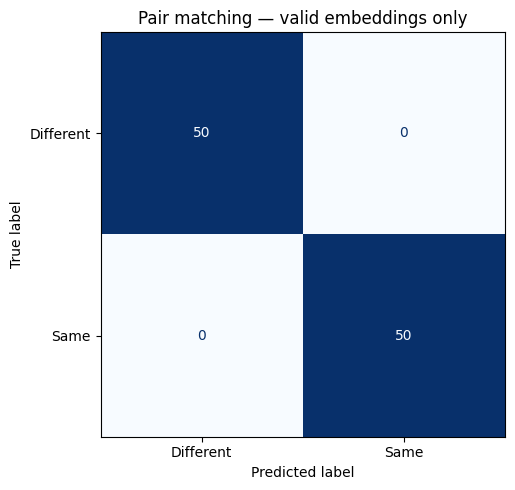

Sensitivity (Same recall): 1.000
Specificity (Different recall): 1.000


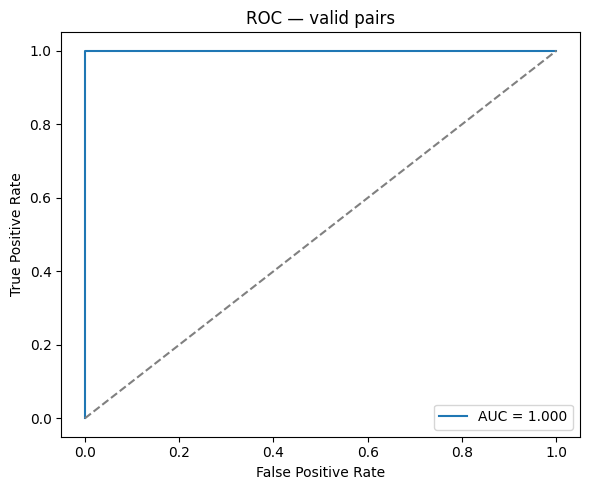

In [23]:
valid_results = pair_results[pair_results["status"] == "ok"].copy()
print(f"Valid pairs for 2-class metrics: {len(valid_results)}/{len(pair_results)}")
if len(valid_results):
    labels = ["Different", "Same"]
    print(classification_report(valid_results["label"], valid_results["prediction"],
                                labels=labels, zero_division=0))
    cm = confusion_matrix(valid_results["label"], valid_results["prediction"], labels=labels)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title("Pair matching — valid embeddings only")
    plt.tight_layout()
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print("Sensitivity (Same recall):", f"{tp / (tp + fn):.3f}" if tp + fn else "N/A")
    print("Specificity (Different recall):", f"{tn / (tn + fp):.3f}" if tn + fp else "N/A")
else:
    print("Không có cặp hợp lệ để tính confusion matrix")

if valid_results["label"].nunique() == 2:
    y_true = (valid_results["label"] == "Same").astype(int)
    fpr, tpr, thresholds = roc_curve(y_true, valid_results["similarity"])
    roc_auc = auc(fpr, tpr)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC — valid pairs")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("ROC/AUC không khả dụng: cần cả cặp Same và Different hợp lệ")


9.3. Phân bố Cosine Similarity

So sánh phân bố độ tương đồng của các cặp Same và Different trên các cặp xử lý thành công. Dataset chưa có nhãn góc mặt/điều kiện ánh sáng theo từng ảnh, nên không kết luận độ chính xác theo điều kiện.

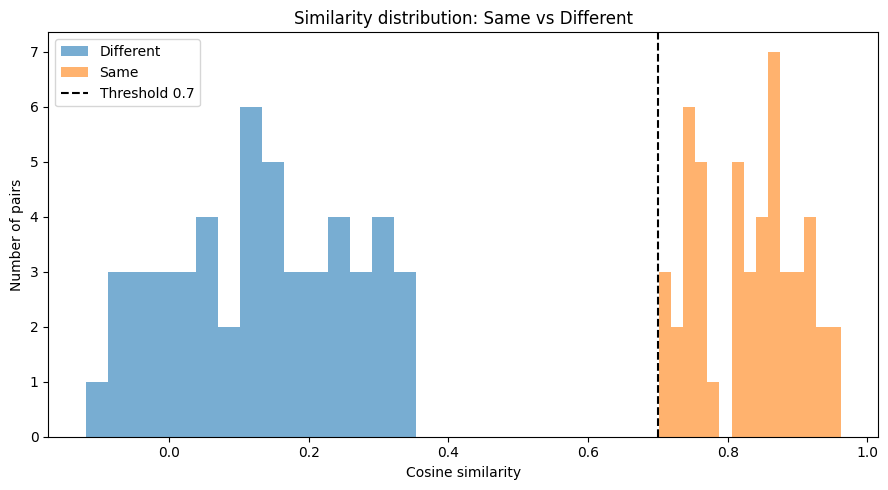

,label,pairs,accuracy,mean_similarity
0,Different,50,1.0,0.133071
1,Same,50,1.0,0.829508


In [24]:
if len(valid_results):
    fig, ax = plt.subplots(figsize=(9, 5))
    for label, group in valid_results.groupby("label"):
        ax.hist(group["similarity"], bins=15, alpha=0.6, label=label)
    ax.axvline(SIMILARITY_THRESHOLD, linestyle="--", color="black", label="Threshold 0.7")
    ax.set(xlabel="Cosine similarity", ylabel="Number of pairs", title="Similarity distribution: Same vs Different")
    ax.legend()
    plt.tight_layout()
    plt.show()
    display(valid_results.groupby("label").agg(
        pairs=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_similarity=("similarity", "mean")
    ).reset_index())
else:
    print("Không có cặp hợp lệ để vẽ phân bố similarity")

9.4. Hiển thị các cặp ảnh đúng và sai

Chọn tối đa 3 cặp đúng và 3 cặp sai. Đây là minh họa kết quả thực tế sau khi chạy, không dùng số liệu giả định.

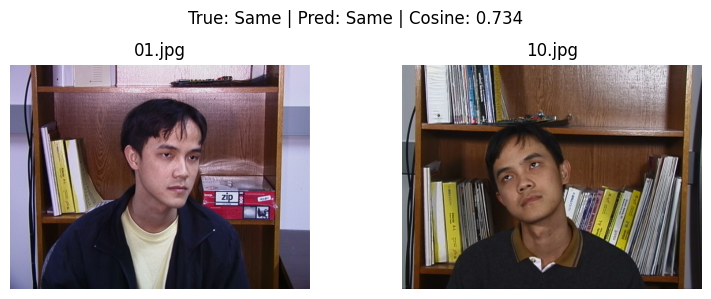

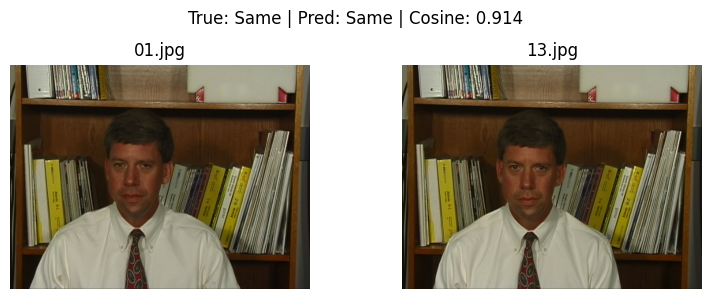

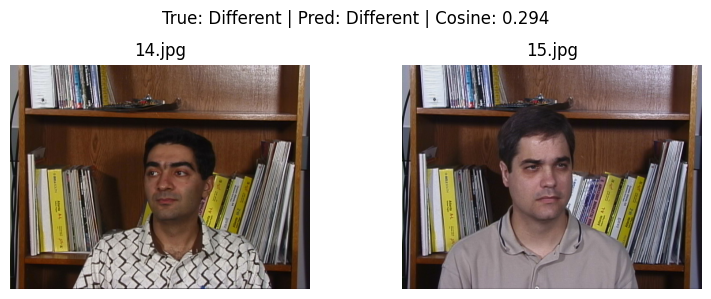

In [25]:
examples = pd.concat([
    pair_results[pair_results.correct].head(3),
    pair_results[~pair_results.correct].head(3)
]).head(6)
for row in examples.itertuples(index=False):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    for ax, filename in zip(axes, [row.image_a, row.image_b]):
        image = cv2.imread(str(resolve_image(filename)))
        if image is not None:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(Path(str(filename).replace("\\", "/")).name)
        ax.axis("off")
    sim = "N/A" if pd.isna(row.similarity) else f"{row.similarity:.3f}"
    fig.suptitle(f"True: {row.label} | Pred: {row.prediction} | Cosine: {sim}")
    plt.tight_layout()
    plt.show()

## 10. Trực quan hóa benchmark webcam

Chạy `python benchmark_webcam.py` từ thư mục gốc trước để tạo CSV trong `outputs/benchmark/`. Notebook chỉ **đọc kết quả**, không tự mở webcam. Trục X là **thứ tự mẫu**, không phải thời gian (giây), vì CSV chứa `sample` và `latency_ms`. FPS đo vòng lặp hiển thị, không phải thông lượng FaceNet.

In [26]:
BENCHMARK_DIR = ROOT / "outputs" / "benchmark"
tracking_csv = BENCHMARK_DIR / "tracking_latency.csv"
recognition_csv = BENCHMARK_DIR / "recognition_latency.csv"
summary_csv = BENCHMARK_DIR / "summary.csv"

for path in (tracking_csv, recognition_csv, summary_csv):
    if not path.exists():
        raise FileNotFoundError(f"Chưa có {path}. Chạy benchmark_webcam.py trước.")

tracking_df = pd.read_csv(tracking_csv)
recognition_df = pd.read_csv(recognition_csv)
summary_df = pd.read_csv(summary_csv)
display(summary_df)

,metric,value
0,duration_s,60.008152
1,frames,1793.000000
2,avg_fps,29.879274
3,tracking_count,1767.000000
4,tracking_mean_ms,2.114380
5,tracking_median_ms,1.793000
6,tracking_min_ms,1.411200
7,tracking_max_ms,5.490300
8,recognition_count,30.000000
9,recognition_mean_ms,776.226603


In [27]:
print("Tracking columns:", tracking_df.columns.tolist())
print("Recognition columns:", recognition_df.columns.tolist())

display(tracking_df.head())
display(recognition_df.head())

Tracking columns: ['sample', 'latency_ms']
Recognition columns: ['sample', 'latency_ms']


,sample,latency_ms
0,1,2.1871
1,2,1.6951
2,3,1.7013
3,4,1.7461
4,5,1.7097


,sample,latency_ms
0,1,837.3241
1,2,782.9041
2,3,764.5706
3,4,757.4628
4,5,761.4041


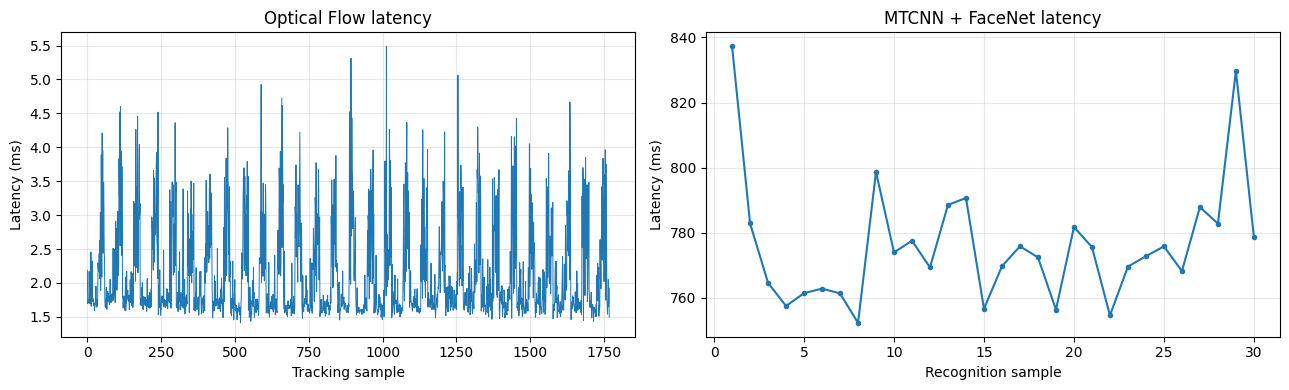

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Tracking latency
axes[0].plot(
    range(1, len(tracking_df) + 1),
    tracking_df["latency_ms"],
    linewidth=0.7
)
axes[0].set(
    title="Optical Flow latency",
    xlabel="Tracking sample",
    ylabel="Latency (ms)"
)

# Recognition latency
axes[1].plot(
    range(1, len(recognition_df) + 1),
    recognition_df["latency_ms"],
    marker="o",
    markersize=3
)
axes[1].set(
    title="MTCNN + FaceNet latency",
    xlabel="Recognition sample",
    ylabel="Latency (ms)"
)

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Kết luận thực nghiệm

Thực nghiệm **pair verification** trên Georgia Tech gồm **100 cặp** (50 Same, 50 Different), sử dụng **91 ảnh duy nhất**. Cả 91 ảnh đều được trích xuất embedding thành công, không có cặp xử lý lỗi. Với ngưỡng cosine 0.70, hệ thống phân loại đúng **100/100 cặp**: Accuracy 100%, Precision/Recall/F1 cho lớp Same đều 1.00, Sensitivity và Specificity đều 1.00. Không ghi nhận False Positive hoặc False Negative trên mẫu đã chọn. Đây không phải độ chính xác tổng quát ngoài thực tế vì tập nhỏ, các cặp có thể dùng chung ảnh và chưa kiểm định trên danh tính/điều kiện độc lập.

Benchmark webcam ghi nhận **60.01 giây**, **1.793 frame**, **29.88 FPS của vòng lặp hiển thị**. Optical Flow có latency trung bình **2.11 ms** (1.767 mẫu), trong khi nhận diện MTCNN + FaceNet trung bình **776.23 ms** (30 mẫu). Việc chạy nhận diện trên luồng nền và tracking ở các frame trung gian giúp duy trì tốc độ hiển thị gần 30 FPS trong lần thử này; không nên hiểu FPS này là số lần FaceNet suy luận mỗi giây.

**Giới hạn:** chưa có ground truth để chấm đúng/sai cho thí nghiệm ba ảnh; chưa đánh giá định lượng độ chính xác tracking; chưa đánh giá đa danh tính, chống giả mạo, thay đổi điều kiện ánh sáng/góc mặt có hệ thống hoặc hiệu chỉnh ngưỡng trên tập validation độc lập. Kết quả phù hợp để minh họa một hệ thống so khớp với **một ảnh tham chiếu**, không đủ cơ sở cho ứng dụng xác thực bảo mật.